In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


In [13]:
raw = pd.read_csv('energy_dataset.csv')
raw['date'] = pd.to_datetime(raw['time'].str.slice(0, 19)).dt.normalize()
raw['time'] = pd.to_datetime(raw['time'], utc=True)
df = raw.set_index('time').sort_index()
display(df.head(5))

expected_timeline = pd.date_range(df.index.min(), df.index.max(), freq='h')
assert df.index.equals(expected_timeline), 'check time'

print('total hours:', len(df))
print('Solar hours missing:', df['generation solar'].isna().sum())

,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage aggregated,...,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual,date
time,,,,,,,,,,,,,,,,,,,,,
2014-12-31 23:00:00+00:00,447.0,329.0,0.0,4844.0,4821.0,162.0,0.0,0.0,0.0,NaN,...,0.0,6378.0,17.0,NaN,6436.0,26118.0,25385.0,50.10,65.41,2015-01-01
2015-01-01 00:00:00+00:00,449.0,328.0,0.0,5196.0,4755.0,158.0,0.0,0.0,0.0,NaN,...,0.0,5890.0,16.0,NaN,5856.0,24934.0,24382.0,48.10,64.92,2015-01-01
2015-01-01 01:00:00+00:00,448.0,323.0,0.0,4857.0,4581.0,157.0,0.0,0.0,0.0,NaN,...,0.0,5461.0,8.0,NaN,5454.0,23515.0,22734.0,47.33,64.48,2015-01-01
2015-01-01 02:00:00+00:00,438.0,254.0,0.0,4314.0,4131.0,160.0,0.0,0.0,0.0,NaN,...,0.0,5238.0,2.0,NaN,5151.0,22642.0,21286.0,42.27,59.32,2015-01-01
2015-01-01 03:00:00+00:00,428.0,187.0,0.0,4130.0,3840.0,156.0,0.0,0.0,0.0,NaN,...,0.0,4935.0,9.0,NaN,4861.0,21785.0,20264.0,38.41,56.04,2015-01-01


total hours: 35064
Solar hours missing: 18


In [25]:
grouped = df.groupby('date')['generation solar']
daily_check = pd.DataFrame({
    'sum_available': grouped.sum(min_count=1),
    'valid_hours': grouped.count(),
    'expected_hours': grouped.size()
})
daily_check['complete'] = daily_check['valid_hours'].eq(daily_check['expected_hours'])
daily = daily_check['sum_available'].where(daily_check['complete']).asfreq('D')
daily.name = 'daily_solar'

print('Total days:', len(daily))
print('Complete days:', daily.notna().sum())
print('Incomplete days:', daily.isna().sum())

display(daily_check['expected_hours'].value_counts().sort_index().to_frame('days'))
print('Incomplete dates')
display(daily_check.loc[~daily_check['complete']])

Total days: 1461
Complete days: 1450
Incomplete days: 11


,days
expected_hours,
23,4
24,1453
25,4


Incomplete dates


,sum_available,valid_hours,expected_hours,complete
date,,,,
2015-01-05,18461.0,17,24,False
2015-01-19,16471.0,22,24,False
2015-01-27,27542.0,23,24,False
2015-01-28,26540.0,23,24,False
2015-04-16,21163.0,23,24,False
2015-04-23,47105.0,23,24,False
2015-06-15,25942.0,23,24,False
2015-10-02,14595.0,23,24,False
2015-12-02,17494.0,23,24,False


In [31]:
montly_mean = daily.groupby(daily.index.month).mean()
seasonal_baseline = daily.groupby(daily.index.month).transform('mean')
adjusted = daily - seasonal_baseline
adjusted.name = 'montly_centered'

display(pd.DataFrame({
    'daily': daily,
    'montly_baseline': seasonal_baseline,
    'adjusted': adjusted
}))

,daily,montly_baseline,adjusted
date,,,
2015-01-01,27443.0,25789.625,1653.375
2015-01-02,30053.0,25789.625,4263.375
2015-01-03,26871.0,25789.625,1081.375
2015-01-04,57660.0,25789.625,31870.375
2015-01-05,NaN,25789.625,NaN
...,...,...,...
2018-12-27,16162.0,22233.000,-6071.000
2018-12-28,13224.0,22233.000,-9009.000
2018-12-29,18126.0,22233.000,-4107.000


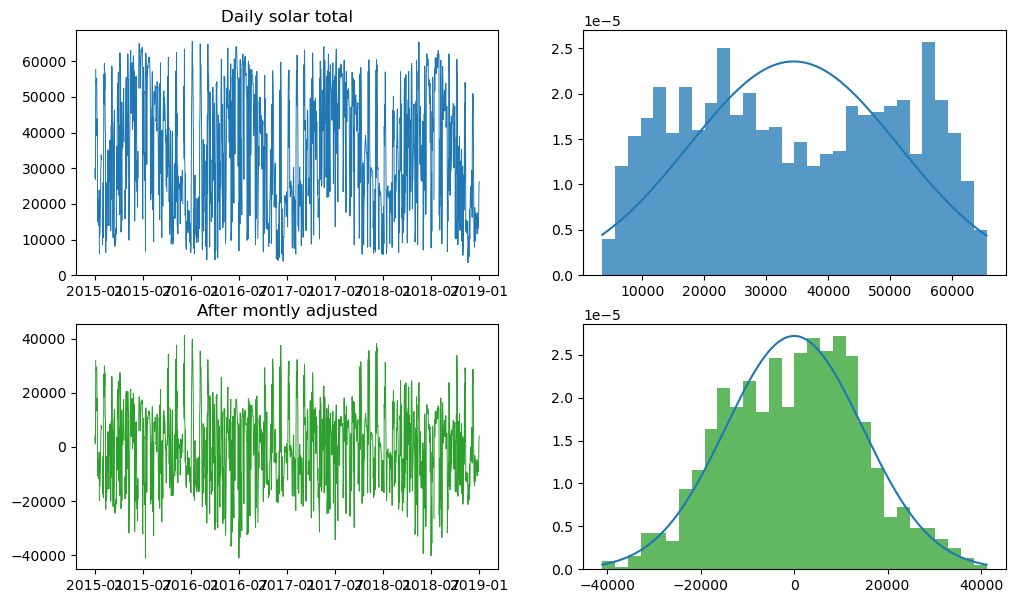

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for row, (series, label, color) in enumerate([(daily, 'Daily solar total', 'tab:blue'), (adjusted, 'After montly adjusted', 'tab:green')]):
    axes[row, 0].plot(series.index, series, linewidth=0.7, color=color)
    axes[row, 0].set_title(label)
    if row == 0:
        axes[row, 0].set_ylim(bottom=0)

    values = series.dropna()
    axes[row, 1].hist(values, bins=30, density=True, color=color, alpha=0.75)
    x = np.linspace(values.min(), values.max(), 300)
    axes[row, 1].plot(x, stats.norm.pdf(x, values.mean(), values.std()))
    